# gdTProfiler tutorial

This tutorial shows how to identify γδ T cells, predict their Vδ1/Vδ2 subtype and score their cell state in a single-cell RNA-seq dataset.

The example data are 1,060 spleen cells from donor A31 of the Cross-tissue Immune Cell Atlas (Domínguez Conde et al., *Science* 2022). For 628 of them, paired TCR sequencing defines whether the cell is an αβ or a γδ T cell, so we can check the predictions against receptor evidence. These cells were not used to train gdTProfiler.

## 1. Load the data

gdTProfiler needs **raw UMI counts** and **gene symbols** as `var_names`. The example dataset is included in the package. For your own data, use `anndata.read_h5ad(...)`; if the counts are in a layer, pass `layer="counts"` to the functions below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdtprofiler as gdt
import gdtprofiler.plotting as pl

adata = gdt.datasets.spleen_example()
adata

AnnData object with n_obs × n_vars = 1060 × 13119
    obs: 'Donor', 'Organ', 'author_annotation', 'receptor_identity', 'receptor_subtype'
    layers: None (.X)

In [2]:
adata.obs["receptor_identity"].value_counts()

receptor_identity
alpha_beta            545
no paired receptor    432
gamma_delta            83
Name: count, dtype: int64

## 2. Predict identity and subtype

`gdt.predict` adds six columns to `adata.obs`:

* `gdT_p_alpha_beta`, `gdT_p_gamma_delta`, `gdT_p_NK`: probabilities of the three classes
* `gdT_class`: the most probable class
* `gdT_call`: `gdT_p_gamma_delta` ≥ 0.5 (the threshold used in the paper)
* `gdT_q_Vdelta1`: Vδ1 score; values near 0 indicate Vδ2. Interpret it only for γδ T cells.

In [3]:
gdt.predict(adata)
adata.obs[["gdT_p_alpha_beta", "gdT_p_gamma_delta", "gdT_p_NK", "gdT_class", "gdT_call", "gdT_q_Vdelta1"]].head()

,gdT_p_alpha_beta,gdT_p_gamma_delta,gdT_p_NK,gdT_class,gdT_call,gdT_q_Vdelta1
Pan_T7917815_AAACCTGAGGCCATAG,0.000205,0.350913,0.648883,NK,False,0.945325
Pan_T7917815_AAACCTGGTCAGCTAT,0.998759,0.000792,0.000449,alpha_beta,False,0.826909
Pan_T7917815_AAACCTGTCTGCCCTA,0.999993,0.000005,0.000001,alpha_beta,False,0.165928
Pan_T7917815_AAACGGGAGGCGATAC,0.000006,0.832949,0.167045,gamma_delta,True,0.990382
Pan_T7917815_AAACGGGCAAGCTGAG,0.000007,0.000016,0.999977,NK,False,0.997983


In [4]:
adata.uns["gdtprofiler"]

{'model': 'softmax_v1',
 'threshold': 0.5,
 'encoder_gene_coverage': 1.0,
 'missing_TCR_genes': []}

`encoder_gene_coverage` is the fraction of the model's 2,000 genes found in your data, and `missing_TCR_genes` lists absent TCR genes. If TRDV or TRGC genes are missing, gdTProfiler warns you, because identity predictions are unreliable without them.

## 3. Compare with receptor evidence

In [5]:
pd.crosstab(adata.obs["receptor_identity"], adata.obs["gdT_class"])

gdT_class,NK,alpha_beta,gamma_delta
receptor_identity,,,
alpha_beta,37,506,2
gamma_delta,6,2,75
no paired receptor,79,317,36


Average precision (γδ vs αβ): 0.991


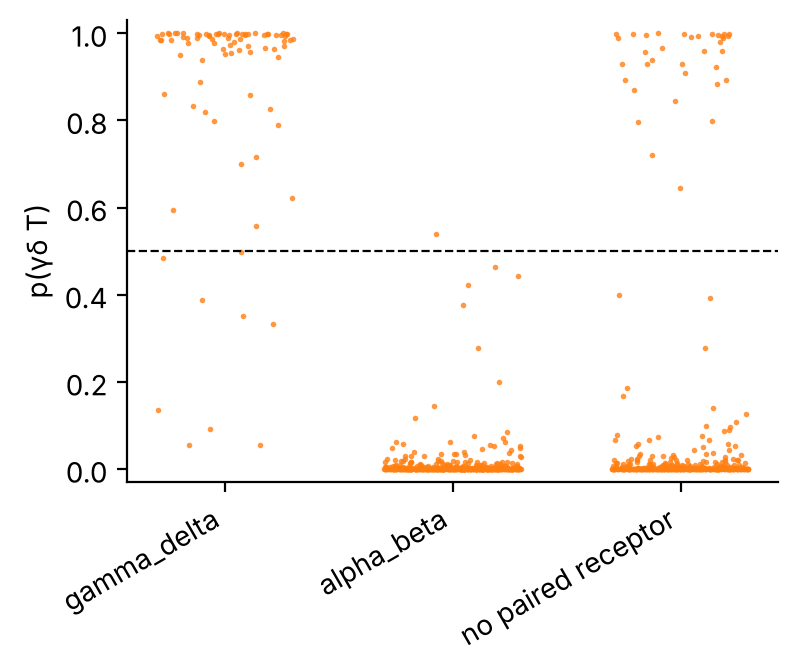

In [6]:
from sklearn.metrics import average_precision_score

ref = adata.obs["receptor_identity"].isin(["alpha_beta", "gamma_delta"])
y = (adata.obs.loc[ref, "receptor_identity"] == "gamma_delta").astype(int)
print("Average precision (γδ vs αβ):", round(average_precision_score(y, adata.obs.loc[ref, "gdT_p_gamma_delta"]), 3))

pl.identity_scores(adata, groupby="receptor_identity")
plt.show()

Cells without paired receptor data can still be scored. Here are the predicted classes for the cells the original authors annotated as NK cells or γδ T cells:

gdT_class            NK  alpha_beta  gamma_delta
author_annotation                               
NK_CD16+              7           0            0
NK_CD56bright_CD16-  49           4            4
Tgd_CRTAM+           17          15           78


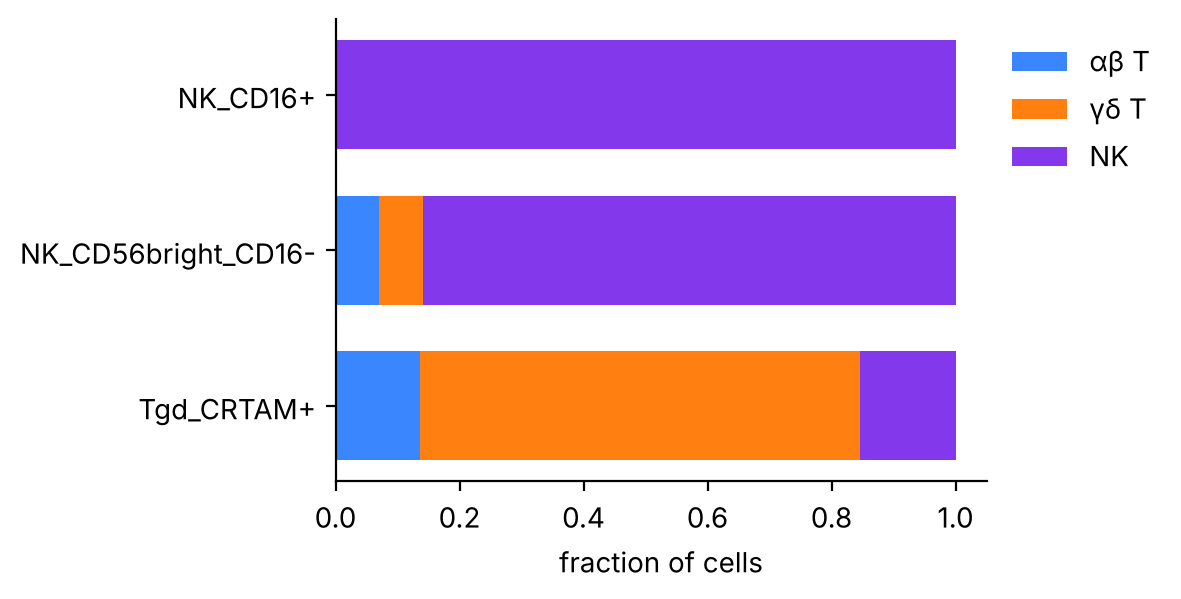

In [7]:
cells = adata.obs["author_annotation"].str.startswith(("NK", "Tgd"))
print(pd.crosstab(adata.obs.loc[cells, "author_annotation"], adata.obs.loc[cells, "gdT_class"]))
pl.class_composition(adata[cells].copy(), groupby="author_annotation")
plt.show()

## 4. Vδ1/Vδ2 subtype

The subtype score is meaningful for γδ T cells. Here we compare it with receptor-defined subtype.

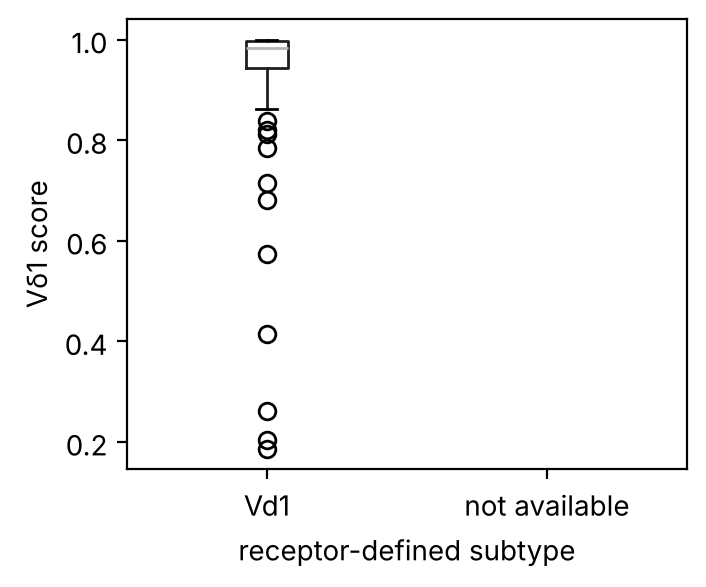

In [8]:
gd = adata.obs["receptor_subtype"].isin(["Vd1", "Vd2"])
fig, ax = plt.subplots(figsize=(3.5, 3))
adata.obs[gd].boxplot(column="gdT_q_Vdelta1", by="receptor_subtype", ax=ax, grid=False)
ax.set_title(""); plt.suptitle(""); ax.set_xlabel("receptor-defined subtype"); ax.set_ylabel("Vδ1 score")
plt.show()

## 5. Cell-state programmes

`gdt.score_programmes` projects each cell onto the eight programmes of the γδ T-cell reference and adds `gdT_P1` … `gdT_P10` (relative usage, summing to 1), `gdT_relative_error` and `gdT_within_q95`. Cells with `gdT_within_q95 = False` are not well described by the reference, so interpret their programme usage with caution.

The programmes were learned from γδ T cells, so usage is most meaningful for predicted γδ T cells; we show all three predicted classes for comparison.

In [9]:
gdt.score_programmes(adata)
programmes = ["gdT_P1", "gdT_P2", "gdT_P3", "gdT_P4", "gdT_P5", "gdT_P7", "gdT_P9", "gdT_P10"]
adata.obs[programmes + ["gdT_relative_error", "gdT_within_q95"]].head()

,gdT_P1,gdT_P2,gdT_P3,gdT_P4,gdT_P5,gdT_P7,gdT_P9,gdT_P10,gdT_relative_error,gdT_within_q95
Pan_T7917815_AAACCTGAGGCCATAG,0.143718,0.648787,0.129034,0.00000,0.000000,0.064780,0.000000,0.013681,0.886458,True
Pan_T7917815_AAACCTGGTCAGCTAT,0.311013,0.121960,0.000000,0.00000,0.266356,0.205095,0.095576,0.000000,0.914032,True
Pan_T7917815_AAACCTGTCTGCCCTA,0.000000,0.254287,0.151309,0.00000,0.445481,0.112340,0.036583,0.000000,0.972068,False
Pan_T7917815_AAACGGGAGGCGATAC,0.530178,0.214076,0.004349,0.06305,0.000000,0.159100,0.029247,0.000000,0.857155,True
Pan_T7917815_AAACGGGCAAGCTGAG,0.472856,0.188350,0.000000,0.00000,0.045146,0.189970,0.103678,0.000000,0.845991,True


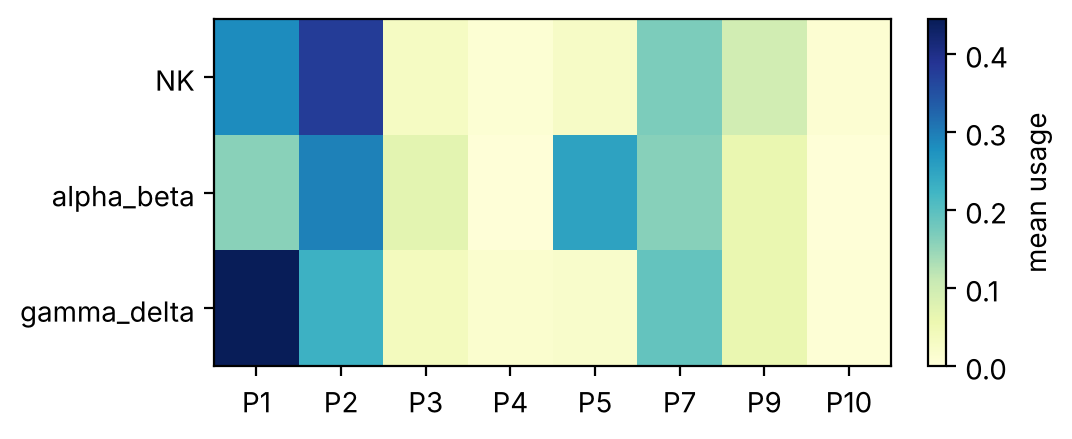

In [10]:
pl.programme_usage(adata, groupby="gdT_class")
plt.show()

## 6. Save the results

In [11]:
adata.obs.to_csv("SPL_donor_A31_gdTProfiler.csv")

## Notes

* Use raw counts. gdTProfiler raises an error for normalized or log-transformed values.
* The 0.5 threshold on `gdT_p_gamma_delta` is the one used in the paper; stricter thresholds (0.7, 0.8) trade recall for precision.
* Probabilities are model scores and are not calibrated for every new dataset.
* For spatial data, check `missing_TCR_genes` first: without TRDV/TRGC probes, identity predictions are unreliable.